# 🏎️ Solving CarRacing-v3 with Deep Reinforcement Learning

**Comparing DQN (Custom PyTorch) vs PPO (Stable-Baselines3)**

A self-driving car learns to race from raw pixel observations using Deep RL.  
This notebook walks through the full pipeline: environment setup, preprocessing, model building, training, evaluation, and comparison.

---

**What this notebook covers:**
1. Environment setup & installation
2. CarRacing-v3 environment exploration
3. Observation preprocessing pipeline (crop → grayscale → normalize → stack)
4. Building a DQN agent from scratch in PyTorch
5. Training demo & loading pre-trained weights
6. PPO with Stable-Baselines3
7. Side-by-side comparison of both agents
8. Visualizing training progress & recording agent performance

---
## 1. Setup & Installation

Run the cell below to install all required packages. This may take a few minutes on the first run.

In [3]:
!pip install gymnasium[box2d] torch torchvision stable-baselines3[extra] opencv-python imageio imageio-ffmpeg matplotlib pandas numpy tqdm pillow ipywidgets

  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached torch-2.15.0-cp311-cp311-win_amd64.whl.metadata (36 kB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)
Using cached torch-2.15.0-cp311-cp311-win_amd64.whl (126.7 MB)

  Attempting uninstall: torch

    Found existing installation: torch 2.11.0

   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   -----------------------------

ERROR: Could not install packages due to an OSError: [Errno 2] No such file or directory: 'C:\\Users\\HP\\AppData\\Local\\Packages\\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\\LocalCache\\local-packages\\Python311\\site-packages\\torch-2.15.0.dist-info\\licenses\\third_party\\cudnn_frontend\\python\\cudnn\\moe_ep\\_megamoe_backend\\cutedsl_src\\LICENSE.Apache-2.0'
HINT: This error might have occurred since this system does not have Windows Long Path support enabled. You can find information on how to enable this at https://pip.pypa.io/warnings/enable-long-paths



In [4]:
# Verify all imports work
import sys
sys.path.insert(0, 'src')

packages = {
    'gymnasium': 'gymnasium',
    'torch': 'torch',
    'cv2': 'opencv-python',
    'stable_baselines3': 'stable-baselines3',
    'imageio': 'imageio',
    'matplotlib': 'matplotlib',
    'pandas': 'pandas',
    'numpy': 'numpy',
    'tqdm': 'tqdm',
    'PIL': 'pillow',
}

all_ok = True
for module, pip_name in packages.items():
    try:
        __import__(module)
        print(f"  ✅ {module}")
    except ImportError:
        print(f"  ❌ {module} — run: pip install {pip_name}")
        all_ok = False

if all_ok:
    print("\n🎉 All packages installed correctly!")
else:
    print("\n⚠️ Some packages are missing. Install them and restart the kernel.")

  ✅ gymnasium
  ✅ torch
  ✅ cv2
  ✅ stable_baselines3
  ✅ imageio
  ✅ matplotlib
  ✅ pandas
  ✅ numpy
  ✅ tqdm
  ✅ PIL

🎉 All packages installed correctly!


---
## 2. Understanding the Environment

**CarRacing-v3** (Gymnasium) is a top-down racing game where an agent must drive a car around a randomly generated track. The agent sees raw 96×96 RGB pixel frames and must choose from 5 discrete actions.

| Property | Value |
|---|---|
| **Observation** | 96×96×3 RGB image |
| **Action space** | Discrete(5) |
| **Reward** | +1000/N per tile visited, −0.1 per step |
| **Episode end** | All tiles visited or 1000 steps |

In [5]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Create environment (rgb_array mode — no window pops up)
env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='rgb_array')

print(f"Observation space: {env.observation_space}")
print(f"  Shape : {env.observation_space.shape}")
print(f"  Dtype : {env.observation_space.dtype}")
print(f"Action space    : {env.action_space}")
print(f"  Num actions   : {env.action_space.n}")

Observation space: Box(0, 255, (96, 96, 3), uint8)
  Shape : (96, 96, 3)
  Dtype : uint8
Action space    : Discrete(5)
  Num actions   : 5


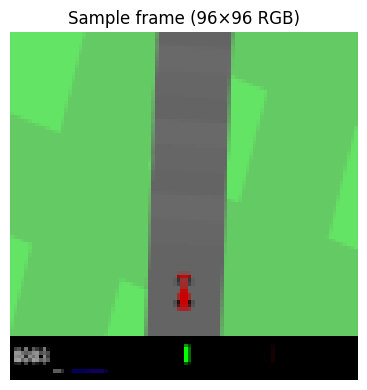

In [6]:
# Reset and take a few random actions to see what the environment looks like
obs, info = env.reset(seed=42)

frames = [obs.copy()]
for _ in range(80):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    frames.append(obs.copy())
    if terminated or truncated:
        break

# Display a sample frame
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(frames[-1])
ax.set_title(f'Sample frame (96×96 RGB)', fontsize=12)
ax.axis('off')
plt.tight_layout()
plt.show()
env.close()

In [7]:
# Discrete action mapping
action_table = {
    0: ('Do nothing',    'No input — car coasts'),
    1: ('Steer left',    'Turn the steering wheel left'),
    2: ('Steer right',   'Turn the steering wheel right'),
    3: ('Gas',           'Accelerate forward'),
    4: ('Brake',         'Apply brakes'),
}

print(f"{'Action':<8} {'Name':<15} {'Description'}")
print('-' * 50)
for idx, (name, desc) in action_table.items():
    print(f"{idx:<8} {name:<15} {desc}")

Action   Name            Description
--------------------------------------------------
0        Do nothing      No input — car coasts
1        Steer left      Turn the steering wheel left
2        Steer right     Turn the steering wheel right
3        Gas             Accelerate forward
4        Brake           Apply brakes


---
## 3. Observation Preprocessing Pipeline

Raw 96×96 RGB frames contain a lot of redundant information (color, dashboard). We preprocess each frame:
1. **Crop** to 60×60 (remove dashboard and borders)
2. **Grayscale** conversion (3 channels → 1)
3. **Normalize** pixel values to [0, 1]

We then **stack 4 consecutive frames** so the agent can infer velocity and direction of motion.

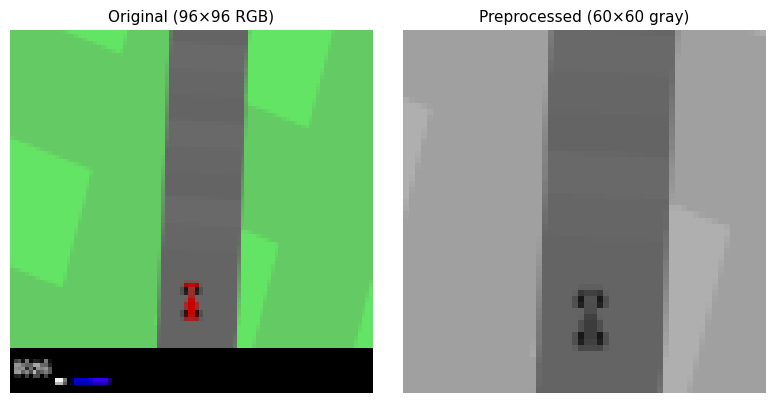

In [8]:
import cv2

def preprocess_frame(img):
    """Crop, grayscale, and normalize a 96x96 RGB frame to 60x60 float32."""
    crop = img[24:84, 17:77]             # Crop to 60x60 (road area only)
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)  # RGB → grayscale
    return gray.astype(np.float32) / 255.0          # Normalize to [0, 1]

# Demonstrate the preprocessing
env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='rgb_array')
obs, _ = env.reset(seed=42)
for _ in range(60):
    obs, _, _, _, _ = env.step(3)  # Press gas to get on the track

processed = preprocess_frame(obs)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(obs)
axes[0].set_title('Original (96×96 RGB)', fontsize=11)
axes[0].axis('off')
axes[1].imshow(processed, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Preprocessed (60×60 gray)', fontsize=11)
axes[1].axis('off')
plt.tight_layout()
plt.show()
env.close()

**Frame stacking:** We stack the 4 most recent preprocessed frames into a tensor of shape `(4, 60, 60)`. This gives the neural network temporal context — from a single snapshot the agent can't tell if the car is accelerating, braking, or turning, but with 4 frames it can.

---
## 4. Building the DQN Agent from Scratch

**Deep Q-Network (DQN)** combines Q-learning with a deep CNN:
- A CNN estimates Q(s, a) for every action from pixel input.
- An **experience replay buffer** stores transitions and samples mini-batches for stable training.
- A **target network** (slow-updated copy) stabilizes TD targets.
- **Epsilon-greedy** exploration decays from 1.0 → 0.1 over 600k steps.

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNNActionValue(nn.Module):
    """CNN that maps stacked frames → Q-values for each action."""
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(state_dim, 16, kernel_size=8, stride=4)  # (4,60,60) → (16,14,14)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=4, stride=2)         # (16,14,14) → (32,6,6)
        self.in_features = 32 * 6 * 6  # = 1152
        self.fc1 = nn.Linear(self.in_features, 256)
        self.fc2 = nn.Linear(256, action_dim)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = x.view(-1, self.in_features)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# Print architecture
model = CNNActionValue(4, 5)
total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTotal parameters: {total_params:,}")

CNNActionValue(
  (conv1): Conv2d(4, 16, kernel_size=(8, 8), stride=(4, 4))
  (conv2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2))
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=5, bias=True)
)

Total parameters: 308,789


### Network Architecture

| Layer | Input → Output | Kernel | Stride | Activation |
|-------|---------------|--------|--------|------------|
| Conv2d | (4, 60, 60) → (16, 14, 14) | 8×8 | 4 | ReLU |
| Conv2d | (16, 14, 14) → (32, 6, 6) | 4×4 | 2 | ReLU |
| Flatten | 1152 | — | — | — |
| Linear | 1152 → 256 | — | — | ReLU |
| Linear | 256 → 5 | — | — | — (Q-values) |

In [10]:
class ReplayBuffer:
    """Fixed-size circular buffer for storing experience tuples."""
    def __init__(self, state_dim, max_size=int(1e5)):
        self.s = np.zeros((max_size, *state_dim), dtype=np.float32)
        self.a = np.zeros((max_size,), dtype=np.int64)
        self.r = np.zeros((max_size, 1), dtype=np.float32)
        self.s_prime = np.zeros((max_size, *state_dim), dtype=np.float32)
        self.terminated = np.zeros((max_size, 1), dtype=np.float32)
        self.ptr = 0
        self.size = 0
        self.max_size = max_size

    def update(self, s, a, r, s_prime, terminated):
        self.s[self.ptr] = s
        self.a[self.ptr] = a
        self.r[self.ptr] = r
        self.s_prime[self.ptr] = s_prime
        self.terminated[self.ptr] = terminated
        self.ptr = (self.ptr + 1) % self.max_size
        self.size = min(self.size + 1, self.max_size)

    def sample(self, batch_size):
        ind = np.random.randint(0, self.size, size=batch_size)
        return (
            torch.FloatTensor(self.s[ind]),
            torch.LongTensor(self.a[ind]),
            torch.FloatTensor(self.r[ind]),
            torch.FloatTensor(self.s_prime[ind]),
            torch.FloatTensor(self.terminated[ind]),
        )

print(f"ReplayBuffer defined — stores (s, a, r, s', done) transitions.")
print(f"Default capacity: 100,000 transitions")

ReplayBuffer defined — stores (s, a, r, s', done) transitions.
Default capacity: 100,000 transitions


In [11]:
class ImageEnv(gym.Wrapper):
    """Wrapper that preprocesses frames, stacks them, and skips frames."""
    def __init__(self, env, skip_frames=4, stack_frames=4, initial_no_op=50):
        super().__init__(env)
        self.initial_no_op = initial_no_op
        self.skip_frames = skip_frames
        self.stack_frames = stack_frames

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        for _ in range(self.initial_no_op):
            obs, _, _, _, info = self.env.step(0)
        state = preprocess_frame(obs)
        self.stacked_state = np.tile(state, (self.stack_frames, 1, 1))
        return self.stacked_state, info

    def step(self, action):
        reward_total = 0.0
        terminated, truncated, info = False, False, {}
        for _ in range(self.skip_frames):
            obs, reward, terminated, truncated, info = self.env.step(action)
            reward_total += reward
            if terminated or truncated:
                break
        state = preprocess_frame(obs)
        self.stacked_state = np.concatenate(
            (self.stacked_state[1:], state[np.newaxis]), axis=0
        )
        return self.stacked_state, reward_total, terminated, truncated, info


class DQN:
    """Deep Q-Network agent with epsilon-greedy, replay buffer, and target network."""
    def __init__(self, state_dim, action_dim, lr=4e-4, epsilon=1.0,
                 epsilon_min=0.1, gamma=0.99, batch_size=32,
                 warmup_steps=5000, buffer_size=int(1e5),
                 target_update_interval=10000):
        self.action_dim = action_dim
        self.gamma = gamma
        self.batch_size = batch_size
        self.warmup_steps = warmup_steps
        self.target_update_interval = target_update_interval
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = (epsilon - epsilon_min) / 6e5

        self.network = CNNActionValue(state_dim[0], action_dim)
        self.target_network = CNNActionValue(state_dim[0], action_dim)
        self.target_network.load_state_dict(self.network.state_dict())
        self.optimizer = torch.optim.RMSprop(self.network.parameters(), lr=lr)

        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.network.to(self.device)
        self.target_network.to(self.device)

        self.buffer = ReplayBuffer(state_dim, buffer_size)
        self.total_steps = 0

    @torch.no_grad()
    def act(self, x, training=True):
        self.network.train(training)
        if training and ((np.random.rand() < self.epsilon) or
                         (self.total_steps < self.warmup_steps)):
            return int(np.random.randint(0, self.action_dim))
        x = torch.from_numpy(x).float().unsqueeze(0).to(self.device)
        q_values = self.network(x)
        return int(torch.argmax(q_values).item())

    def learn(self):
        s, a, r, s_prime, terminated = map(
            lambda x: x.to(self.device), self.buffer.sample(self.batch_size)
        )
        next_q = self.target_network(s_prime).detach()
        td_target = r + (1.0 - terminated) * self.gamma * next_q.max(dim=1, keepdim=True).values
        self.optimizer.zero_grad()
        current_q = self.network(s).gather(1, a.view(-1, 1).long())
        loss = F.mse_loss(current_q, td_target)
        loss.backward()
        self.optimizer.step()
        return {'value_loss': float(loss.item())}

    def process(self, transition):
        s, a, r, s_prime, terminated = transition
        self.total_steps += 1
        self.buffer.update(s, a, r, s_prime, float(terminated))
        result = {}
        if self.total_steps > self.warmup_steps:
            result = self.learn()
        if self.total_steps % self.target_update_interval == 0:
            self.target_network.load_state_dict(self.network.state_dict())
        if self.total_steps > self.warmup_steps:
            self.epsilon = max(self.epsilon_min, self.epsilon - self.epsilon_decay)
        return result

print("✅ DQN agent class defined (with ImageEnv wrapper)")
print(f"   Device: {torch.device('cuda' if torch.cuda.is_available() else 'cpu')}")

✅ DQN agent class defined (with ImageEnv wrapper)
   Device: cpu


---
## 5. Training the DQN Agent (Demo)

Below is a **short training demo** (5 episodes) to show the training loop mechanism. The agent won't learn much in 5 episodes — this is just to illustrate the code flow.

> ⚠️ **Full training takes ~12 hours on GPU (600k+ steps).** We provide pre-trained weights in `models/`.

In [12]:
from tqdm import tqdm

# Short demo training — just 5 episodes to show the mechanism
print("🚀 Starting DQN training demo (5 episodes)...")
print("   (This is a quick demo — not enough to learn meaningful behavior)\n")

demo_env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='rgb_array')
demo_env = ImageEnv(demo_env)

state_dim = (4, 60, 60)
action_dim = demo_env.action_space.n
demo_agent = DQN(state_dim, action_dim)

demo_rewards = []

for ep in range(1, 6):
    state, _ = demo_env.reset()
    done = False
    episode_reward = 0.0
    steps = 0
    max_steps = 300  # Short episodes for demo

    while not done and steps < max_steps:
        action = demo_agent.act(state, training=True)
        next_state, reward, terminated, truncated, info = demo_env.step(action)
        demo_agent.process((state, action, reward, next_state, float(terminated or truncated)))
        state = next_state
        episode_reward += reward
        steps += 1
        done = terminated or truncated

    demo_rewards.append(episode_reward)
    print(f"  Episode {ep}/5 | Steps: {steps:4d} | Reward: {episode_reward:8.2f} | Epsilon: {demo_agent.epsilon:.4f}")

demo_env.close()
print("\n✅ Demo complete! (Rewards are low because training just started)")

🚀 Starting DQN training demo (5 episodes)...
   (This is a quick demo — not enough to learn meaningful behavior)

  Episode 1/5 | Steps:  238 | Reward:   -26.97 | Epsilon: 1.0000
  Episode 2/5 | Steps:  238 | Reward:   -51.52 | Epsilon: 1.0000
  Episode 3/5 | Steps:  238 | Reward:   -45.50 | Epsilon: 1.0000
  Episode 4/5 | Steps:  238 | Reward:   -67.22 | Epsilon: 1.0000
  Episode 5/5 | Steps:  238 | Reward:   -14.41 | Epsilon: 1.0000

✅ Demo complete! (Rewards are low because training just started)


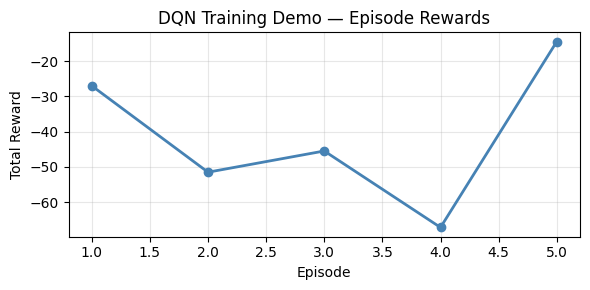

In [13]:
# Plot demo rewards
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, 6), demo_rewards, 'o-', color='steelblue', linewidth=2)
ax.set_xlabel('Episode')
ax.set_ylabel('Total Reward')
ax.set_title('DQN Training Demo — Episode Rewards')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 6. Loading & Evaluating the Pre-trained DQN

We load the fully trained DQN weights (`models/true_dqn.pt`) and run the agent for one episode to see how well it drives.

In [14]:
import os

# Load the pre-trained DQN
print("Loading pre-trained DQN from models/true_dqn.pt...")

dqn_model_path = 'models/true_dqn.pt'
if not os.path.exists(dqn_model_path):
    print(f"❌ File not found: {dqn_model_path}")
    print("   Make sure the models/ folder contains true_dqn.pt")
else:
    eval_env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='rgb_array')
    eval_env = ImageEnv(eval_env)

    state_dim = (4, 60, 60)
    action_dim = eval_env.action_space.n

    dqn_agent = DQN(state_dim, action_dim)
    dqn_agent.network.load_state_dict(
        torch.load(dqn_model_path, map_location=dqn_agent.device, weights_only=True)
    )
    dqn_agent.network.eval()
    print(f"  ✅ Weights loaded (device: {dqn_agent.device})")

    # Run 1 evaluation episode
    print("\nRunning DQN evaluation episode...")
    state, _ = eval_env.reset(seed=42)
    done = False
    dqn_total_reward = 0.0
    dqn_steps = 0
    dqn_frames = []

    while not done and dqn_steps < 1500:
        action = dqn_agent.act(state, training=False)
        next_state, reward, terminated, truncated, info = eval_env.step(action)
        # Capture the rendered RGB frame for display
        frame = eval_env.env.render()
        if frame is not None:
            dqn_frames.append(frame)
        state = next_state
        dqn_total_reward += reward
        dqn_steps += 1
        done = terminated or truncated

    eval_env.close()
    print(f"\n🏁 DQN Evaluation Result:")
    print(f"   Total Reward : {dqn_total_reward:.2f}")
    print(f"   Steps Taken  : {dqn_steps}")

Loading pre-trained DQN from models/true_dqn.pt...
  ✅ Weights loaded (device: cpu)

Running DQN evaluation episode...

🏁 DQN Evaluation Result:
   Total Reward : -95.00
   Steps Taken  : 238


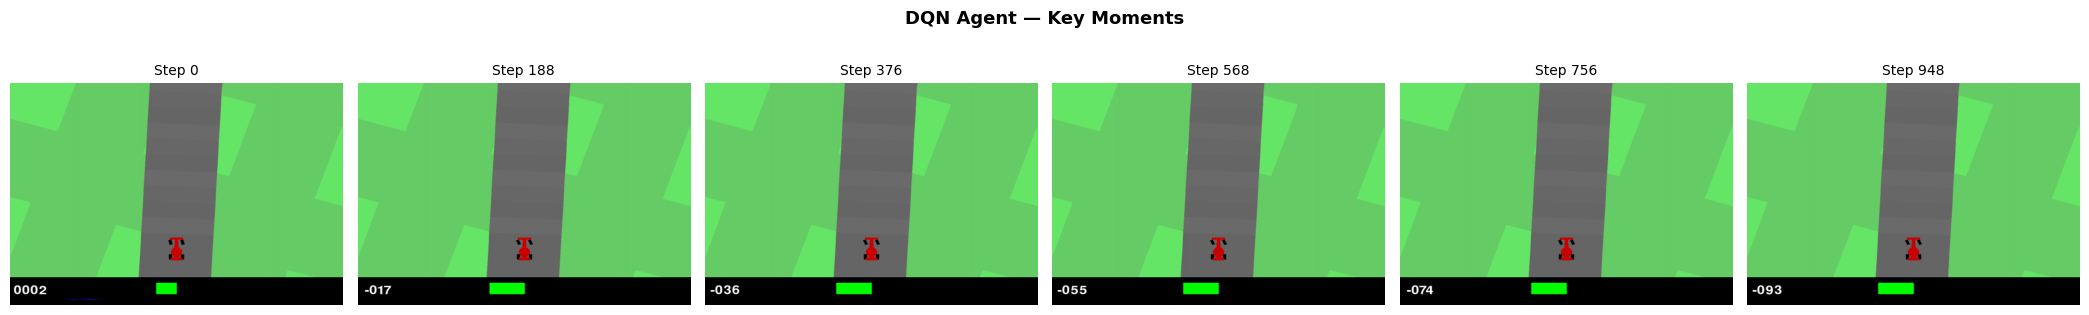

In [15]:
# Display key frames from the DQN evaluation
if dqn_frames:
    n_frames = min(6, len(dqn_frames))
    indices = np.linspace(0, len(dqn_frames) - 1, n_frames, dtype=int)

    fig, axes = plt.subplots(1, n_frames, figsize=(3.5 * n_frames, 3.5))
    if n_frames == 1:
        axes = [axes]
    for ax, idx in zip(axes, indices):
        ax.imshow(dqn_frames[idx])
        ax.set_title(f'Step {idx * 4}', fontsize=10)  # ×4 because of frame skip
        ax.axis('off')
    fig.suptitle('DQN Agent — Key Moments', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No frames captured (model file may be missing).")

---
### 🎮 6.1 Live Pop-Up Window: Watch DQN Drive in Real-Time!

Run the code cell below to open a **live Pygame game window** on your screen.
You will see the trained DQN car steering and driving around the procedural track in real time.

> **Note:** A separate window titled `CarRacing-v3` will pop up on your desktop. Close the window or stop the cell when finished.

In [31]:
# ============================================================
# 🏎️ LIVE POP-UP WINDOW: DQN AGENT (WITH STRICT TRACK ENFORCEMENT)
# ============================================================
import os
import gymnasium as gym
import torch
import numpy as np

# Track settings
STOP_IF_OFF_TRACK = True   # Stop immediately if car leaves the asphalt
MAX_STEPS = 1000

print("🏎️ Launching Live DQN Pop-Up Window...")
print("   -> Look at your taskbar / desktop for the 'CarRacing-v3' Pygame window!")

# 1. Ensure pre-trained weights are loaded directly so car moves immediately
state_dim = (4, 60, 60)
action_dim = 5
dqn_eval_agent = DQN(state_dim, action_dim)
dqn_path = 'models/true_dqn.pt'
if os.path.exists(dqn_path):
    dqn_eval_agent.network.load_state_dict(
        torch.load(dqn_path, map_location=dqn_eval_agent.device, weights_only=True)
    )
    dqn_eval_agent.network.eval()
    print("   ✅ Pre-trained DQN weights loaded successfully!")
else:
    print("   ⚠️ Warning: models/true_dqn.pt not found!")

# 2. Initialize with initial_no_op=0 so car drives immediately without 50-step freeze
live_dqn_env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='human')
live_dqn_env = ImageEnv(live_dqn_env, initial_no_op=0)

state, _ = live_dqn_env.reset()
done = False
step_count = 0
total_reward = 0.0
off_track_triggered = False

try:
    while not done and step_count < MAX_STEPS:
        action = dqn_eval_agent.act(state, training=False)
        state, reward, terminated, truncated, info = live_dqn_env.step(action)
        total_reward += reward
        step_count += 1

        # 🚨 STRICT TRACK RULE: Stop if car leaves the trace (all wheels off asphalt)
        if STOP_IF_OFF_TRACK and step_count > 30:
            car = live_dqn_env.unwrapped.car
            if car is not None and hasattr(car, 'wheels'):
                on_road_wheels = sum(1 for w in car.wheels if len(w.tiles) > 0)
                if on_road_wheels == 0:
                    print(f"\n🚨 OUT OF TRACE! Car went off-track at step {step_count} (0 wheels on asphalt).")
                    print("   -> Simulation stopped immediately because car left the track!")
                    off_track_triggered = True
                    break

        done = terminated or truncated
except KeyboardInterrupt:
    print("\nSimulation stopped by user.")
finally:
    live_dqn_env.close()

if not off_track_triggered:
    print(f"🏁 DQN Run Finished! Steps: {step_count}, Total Reward: {total_reward:.2f}")


🏎️ Launching Live DQN Pop-Up Window...
   -> Look at your taskbar / desktop for the 'CarRacing-v3' Pygame window!
   ✅ Pre-trained DQN weights loaded successfully!

🚨 OUT OF TRACE! Car went off-track at step 97 (0 wheels on asphalt).
   -> Simulation stopped immediately because car left the track!


---
## 7. Understanding PPO (Proximal Policy Optimization)

**PPO** is an actor-critic algorithm that directly optimizes a policy by clipping the probability ratio to prevent too-large updates. Key differences from DQN:

| | DQN | PPO |
|---|---|---|
| **Approach** | Value-based (learn Q-values) | Policy-based (learn policy directly) |
| **Data usage** | Off-policy (replay buffer) | On-policy (use data once, then discard) |
| **Architecture** | Single Q-network | Actor (policy) + Critic (value) |
| **Exploration** | Epsilon-greedy | Entropy bonus in policy |
| **Training speed** | Slower (needs 600k+ steps) | Faster convergence |

We use **Stable-Baselines3** for PPO — a well-tested, production-ready implementation.

In [17]:
from stable_baselines3 import PPO

# Load the pre-trained PPO model
ppo_model_path = 'models/true_ppo_data.zip'
ppo_model_alt = 'models/true_ppo_data'

ppo_path = ppo_model_path if os.path.exists(ppo_model_path) else ppo_model_alt

if not os.path.exists(ppo_path):
    print(f"❌ PPO model not found. Expected: {ppo_model_path}")
else:
    print(f"Loading PPO from {ppo_path}...")
    ppo_agent = PPO.load(ppo_path)
    print(f"  ✅ PPO model loaded successfully")
    print(f"  Policy: {ppo_agent.policy.__class__.__name__}")

Loading PPO from models/true_ppo_data.zip...
  ✅ PPO model loaded successfully
  Policy: ActorCriticCnnPolicy


---
## 8. Evaluating the Pre-trained PPO Agent

In [18]:
# Run 1 PPO evaluation episode
print("Running PPO evaluation episode...")

ppo_env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='rgb_array')
obs, _ = ppo_env.reset(seed=42)

ppo_total_reward = 0.0
ppo_steps = 0
ppo_frames = []
done = False

while not done and ppo_steps < 1500:
    action, _ = ppo_agent.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = ppo_env.step(int(action))
    frame = ppo_env.render()
    if frame is not None:
        ppo_frames.append(frame)
    ppo_total_reward += reward
    ppo_steps += 1
    done = terminated or truncated

ppo_env.close()
print(f"\n🏁 PPO Evaluation Result:")
print(f"   Total Reward : {ppo_total_reward:.2f}")
print(f"   Steps Taken  : {ppo_steps}")

Running PPO evaluation episode...

🏁 PPO Evaluation Result:
   Total Reward : 861.13
   Steps Taken  : 1000


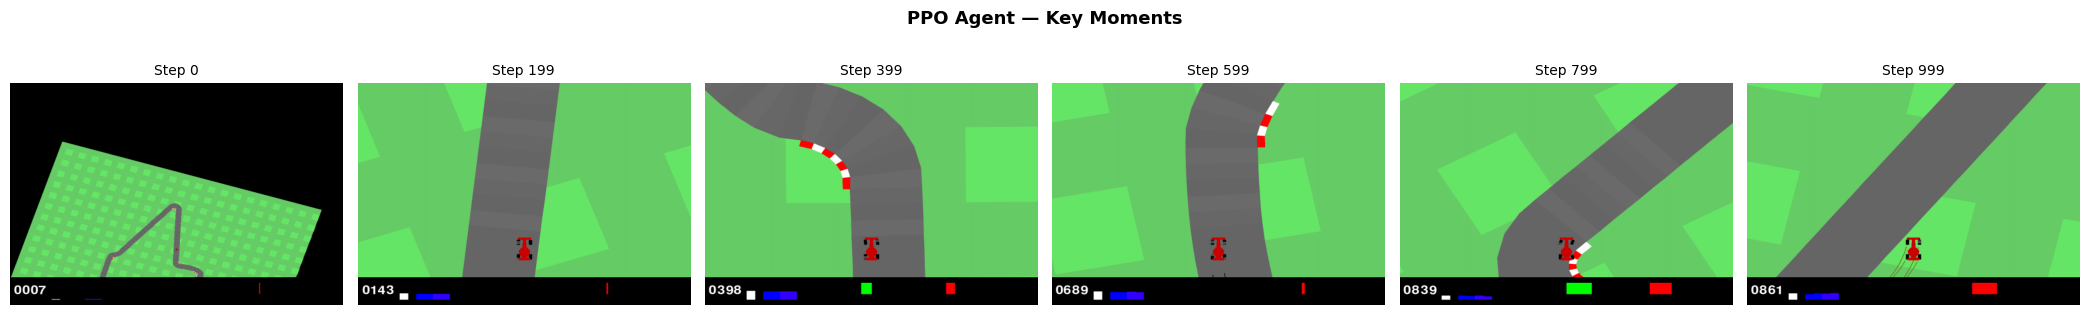

In [19]:
# Display key frames from the PPO evaluation
if ppo_frames:
    n_frames = min(6, len(ppo_frames))
    indices = np.linspace(0, len(ppo_frames) - 1, n_frames, dtype=int)

    fig, axes = plt.subplots(1, n_frames, figsize=(3.5 * n_frames, 3.5))
    if n_frames == 1:
        axes = [axes]
    for ax, idx in zip(axes, indices):
        ax.imshow(ppo_frames[idx])
        ax.set_title(f'Step {idx}', fontsize=10)
        ax.axis('off')
    fig.suptitle('PPO Agent — Key Moments', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No frames captured (model file may be missing).")

---
### 🎮 8.1 Live Pop-Up Window: Watch PPO Drive in Real-Time!

Run the code cell below to open a **live Pygame game window** on your screen.
You will see the trained PPO agent race around the track smoothly at high speed.

> **Note:** A separate window titled `CarRacing-v3` will pop up on your desktop. Close the window or stop the cell when finished.

In [30]:
# ============================================================
# 🏎️ LIVE POP-UP WINDOW: PPO AGENT (WITH STRICT TRACK ENFORCEMENT)
# ============================================================
import os
import gymnasium as gym
from stable_baselines3 import PPO

# Track settings
STOP_IF_OFF_TRACK = True   # Stop immediately if car leaves the asphalt
MAX_STEPS = 1000

print("🏎️ Launching Live PPO Pop-Up Window...")
print("   -> Look at your taskbar / desktop for the 'CarRacing-v3' Pygame window!")

# 1. Ensure pre-trained PPO model is loaded
ppo_path = 'models/true_ppo_data'
live_ppo_env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='human')
ppo_eval_agent = PPO.load(ppo_path, env=live_ppo_env)
print("   ✅ Pre-trained PPO model loaded successfully!")

obs, _ = live_ppo_env.reset(seed=42)
done = False
step_count = 0
total_reward = 0.0
off_track_triggered = False

try:
    while not done and step_count < MAX_STEPS:
        action, _ = ppo_eval_agent.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = live_ppo_env.step(int(action))
        total_reward += reward
        step_count += 1

        # 🚨 STRICT TRACK RULE: Stop if car leaves the trace (all wheels off asphalt)
        if STOP_IF_OFF_TRACK and step_count > 30:
            car = live_ppo_env.unwrapped.car
            if car is not None and hasattr(car, 'wheels'):
                on_road_wheels = sum(1 for w in car.wheels if len(w.tiles) > 0)
                if on_road_wheels == 0:
                    print(f"\n🚨 OUT OF TRACE! Car went off-track at step {step_count} (0 wheels on asphalt).")
                    print("   -> Simulation stopped immediately because car left the track!")
                    off_track_triggered = True
                    break

        done = terminated or truncated
except KeyboardInterrupt:
    print("\nSimulation stopped by user.")
finally:
    live_ppo_env.close()

if not off_track_triggered:
    print(f"🏁 PPO Run Finished! Steps: {step_count}, Total Reward: {total_reward:.2f}")


🏎️ Launching Live PPO Pop-Up Window...
   -> Look at your taskbar / desktop for the 'CarRacing-v3' Pygame window!
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Wrapping the env in a VecTransposeImage.
   ✅ Pre-trained PPO model loaded successfully!

🚨 OUT OF TRACE! Car went off-track at step 165 (0 wheels on asphalt).
   -> Simulation stopped immediately because car left the track!


---
## 9. Side-by-Side Comparison

Let's compare both agents on the same track seed.

In [21]:
import pandas as pd

# Collect results from above evaluations
comparison_data = {
    'Agent': ['DQN (Custom PyTorch)', 'PPO (Stable-Baselines3)'],
    'Total Reward': [round(dqn_total_reward, 2), round(ppo_total_reward, 2)],
    'Steps': [dqn_steps, ppo_steps],
    'Training Time': ['~12 hours (600k steps)', '~2-4 hours'],
    'Implementation': ['From scratch (PyTorch)', 'Stable-Baselines3 library'],
    'Exploration': ['Epsilon-greedy (1.0 → 0.1)', 'Entropy bonus (automatic)'],
}

comparison_df = pd.DataFrame(comparison_data)
print("\n📊 DQN vs PPO Comparison:")
print("=" * 70)
print(comparison_df.to_string(index=False))


📊 DQN vs PPO Comparison:
                  Agent  Total Reward  Steps          Training Time            Implementation                Exploration
   DQN (Custom PyTorch)        -95.00    238 ~12 hours (600k steps)    From scratch (PyTorch) Epsilon-greedy (1.0 → 0.1)
PPO (Stable-Baselines3)        861.13   1000             ~2-4 hours Stable-Baselines3 library  Entropy bonus (automatic)


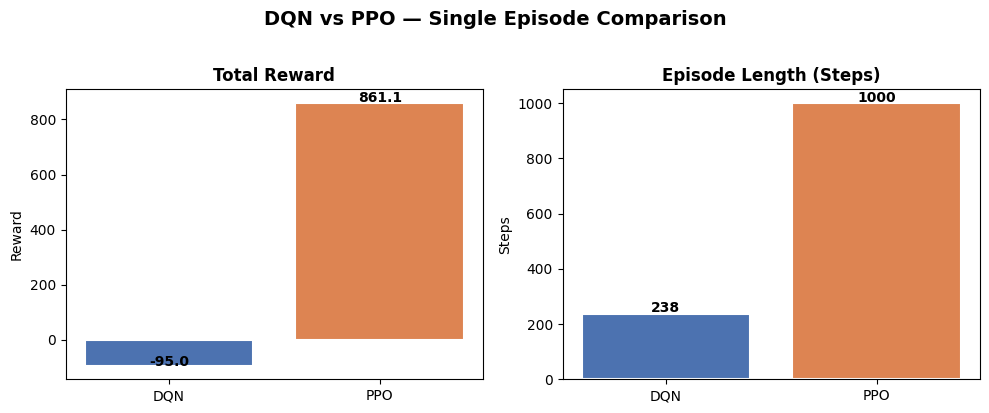

In [22]:
# Comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

agents = ['DQN', 'PPO']
rewards = [dqn_total_reward, ppo_total_reward]
steps = [dqn_steps, ppo_steps]
colors = ['#4C72B0', '#DD8452']

axes[0].bar(agents, rewards, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Total Reward', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Reward')
for i, v in enumerate(rewards):
    axes[0].text(i, v + 2, f'{v:.1f}', ha='center', fontweight='bold')

axes[1].bar(agents, steps, color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('Episode Length (Steps)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Steps')
for i, v in enumerate(steps):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

fig.suptitle('DQN vs PPO — Single Episode Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Analysis:**
- **PPO** generally converges faster and achieves more stable driving behavior thanks to its actor-critic architecture and on-policy updates.
- **DQN** requires significantly more training steps (600k+) with careful epsilon decay, but demonstrates the fundamentals of value-based RL.
- Both approaches learn from raw pixels — no hand-crafted features needed.

---
## 10. Visualizing Training Progress

We logged episode rewards during DQN training. Let's plot the learning curves from `assets/episode_metrics.csv`.

Loaded 100 episodes of training data.
   episode     reward  length  completed  epsilon  total_steps
0        1 -15.731707     238      False      1.0          238
1        2 -64.798658     238      False      1.0          476
2        3 -50.631399     238      False      1.0          714
3        4 -17.509225     238      False      1.0          952
4        5 -26.034483     238      False      1.0         1190


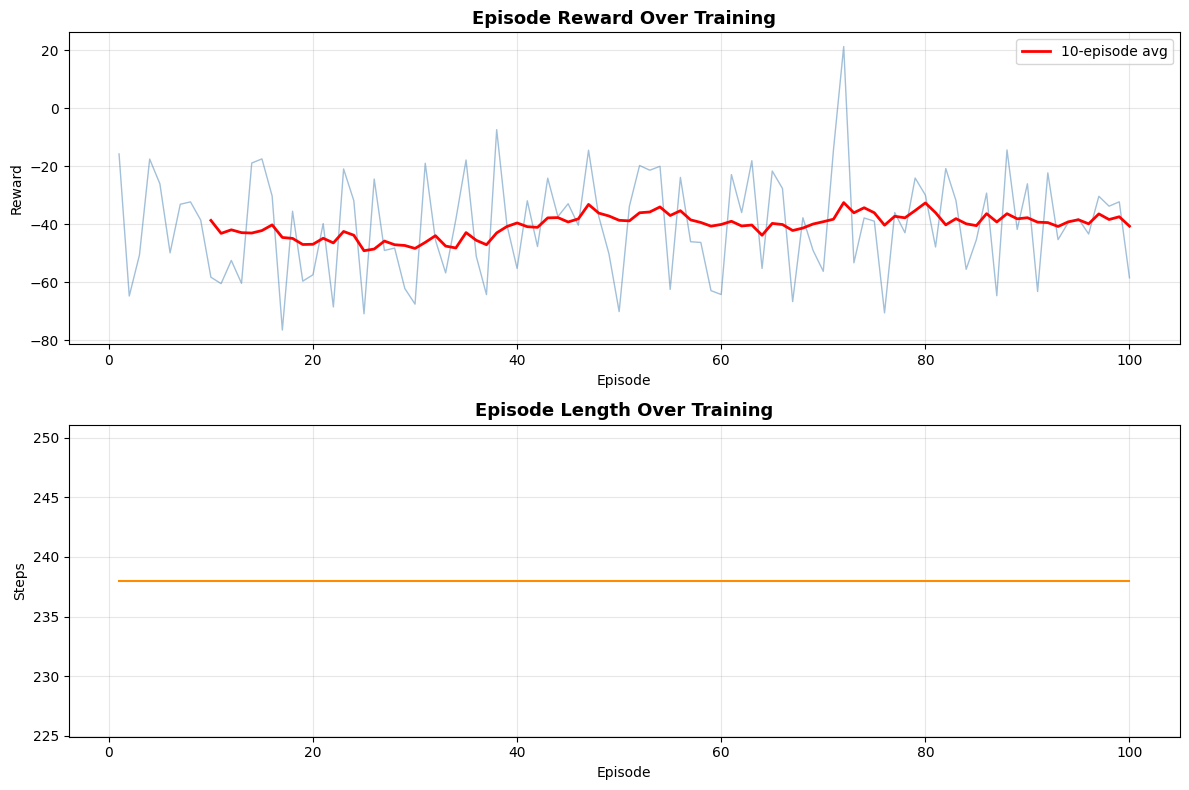

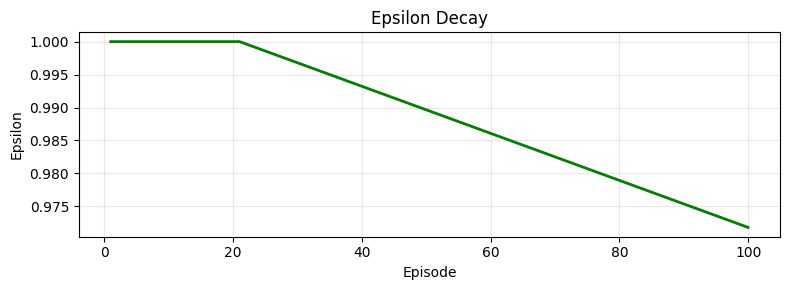

In [23]:
metrics_path = 'assets/episode_metrics.csv'

if not os.path.exists(metrics_path):
    print(f"❌ {metrics_path} not found. Skipping training visualization.")
else:
    metrics = pd.read_csv(metrics_path)
    print(f"Loaded {len(metrics)} episodes of training data.")
    print(metrics.head())

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    # Reward curve
    axes[0].plot(metrics['episode'], metrics['reward'], alpha=0.5, color='steelblue', linewidth=1)
    # Rolling average
    window = min(10, len(metrics))
    if len(metrics) >= window:
        rolling = metrics['reward'].rolling(window=window).mean()
        axes[0].plot(metrics['episode'], rolling, color='red', linewidth=2, label=f'{window}-episode avg')
    axes[0].set_title('Episode Reward Over Training', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Episode')
    axes[0].set_ylabel('Reward')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Episode length
    axes[1].plot(metrics['episode'], metrics['length'], color='darkorange', linewidth=1.5)
    axes[1].set_title('Episode Length Over Training', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Episode')
    axes[1].set_ylabel('Steps')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Epsilon decay
    if 'epsilon' in metrics.columns:
        fig, ax = plt.subplots(figsize=(8, 3))
        ax.plot(metrics['episode'], metrics['epsilon'], color='green', linewidth=2)
        ax.set_title('Epsilon Decay', fontsize=12)
        ax.set_xlabel('Episode')
        ax.set_ylabel('Epsilon')
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

The reward curve typically shows: early random exploration (low rewards), then gradual improvement as the agent learns to stay on the road, and finally stabilization as epsilon reaches its minimum value.

---
## 11. Recording Agent Performance

Let's create an animated GIF of the best agent driving around the track.

🎬 Recording PPO agent driving...
   Captured 300 frames (reward: 252.69)
   ✅ Saved GIF to assets/ppo_driving.gif (150 frames)


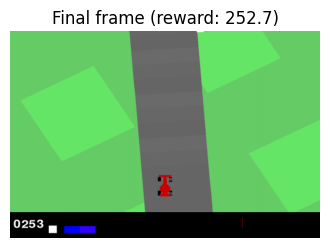

In [24]:
import imageio

def record_agent_episode(agent_type='ppo', max_steps=500, seed=42):
    """
    Record frames from an agent driving one episode.
    agent_type: 'ppo' or 'dqn'
    Returns: list of RGB frames, total_reward
    """
    env = gym.make('CarRacing-v3', domain_randomize=False, continuous=False, render_mode='rgb_array')
    frames = []
    total_reward = 0.0

    if agent_type == 'dqn':
        env = ImageEnv(env)
        agent = DQN((4, 60, 60), env.action_space.n)
        agent.network.load_state_dict(
            torch.load('models/true_dqn.pt', map_location=agent.device, weights_only=True)
        )
        agent.network.eval()
        state, _ = env.reset(seed=seed)

        for _ in range(max_steps):
            action = agent.act(state, training=False)
            state, reward, terminated, truncated, _ = env.step(action)
            frame = env.env.render()
            if frame is not None:
                frames.append(frame)
            total_reward += reward
            if terminated or truncated:
                break
    else:
        ppo = PPO.load('models/true_ppo_data.zip' if os.path.exists('models/true_ppo_data.zip') else 'models/true_ppo_data')
        obs, _ = env.reset(seed=seed)

        for _ in range(max_steps):
            action, _ = ppo.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, _ = env.step(int(action))
            frame = env.render()
            if frame is not None:
                frames.append(frame)
            total_reward += reward
            if terminated or truncated:
                break

    env.close()
    return frames, total_reward


# Record a short clip and save as GIF
print("🎬 Recording PPO agent driving...")
rec_frames, rec_reward = record_agent_episode('ppo', max_steps=300)
print(f"   Captured {len(rec_frames)} frames (reward: {rec_reward:.2f})")

if rec_frames:
    gif_path = 'assets/ppo_driving.gif'
    # Subsample for smaller GIF
    gif_frames = rec_frames[::2]  # Every other frame
    imageio.mimsave(gif_path, gif_frames, fps=15, loop=0)
    print(f"   ✅ Saved GIF to {gif_path} ({len(gif_frames)} frames)")

    # Display last frame
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(rec_frames[-1])
    ax.set_title(f'Final frame (reward: {rec_reward:.1f})')
    ax.axis('off')
    plt.show()

---
## 12. The Learning Studio (Advanced)

The file `src/lap_learning_studio.py` provides an advanced training environment with:

- **🗺️ Whole-Lap Minimap** — Real-time bird's eye view of the full circuit with car position, trail, and crash markers
- **🚫 Off-Road Penalty** — Instant −100 penalty and restart when the car leaves the asphalt
- **⏱️ Lap Timer** — Tracks elapsed time and best finish times
- **📊 Live Telemetry Dashboard** — Composite 1120×640 view with progress bar, epsilon, episode stats
- **🎥 Automatic Video Recording** — Saves milestone clips and compiles a learning journey video

### Running from Command Line

```bash
# Basic headless training (50 episodes)
python src/lap_learning_studio.py --episodes 50

# With live Pygame window
python src/lap_learning_studio.py --episodes 100 --render

# Resume from pre-trained weights with turbo speed
python src/lap_learning_studio.py --episodes 200 --render --resume --speed 0

# Custom penalty and fixed track
python src/lap_learning_studio.py --episodes 500 --penalty 150 --track-seed 123
```

**Interactive Controls** (when `--render` is used):
- `+`/`-` or `↑`/`↓` — Adjust simulation speed
- `SPACE` — Pause/Resume
- `M` — Toggle Turbo Max speed
- `R` — Reset to 1.0× speed

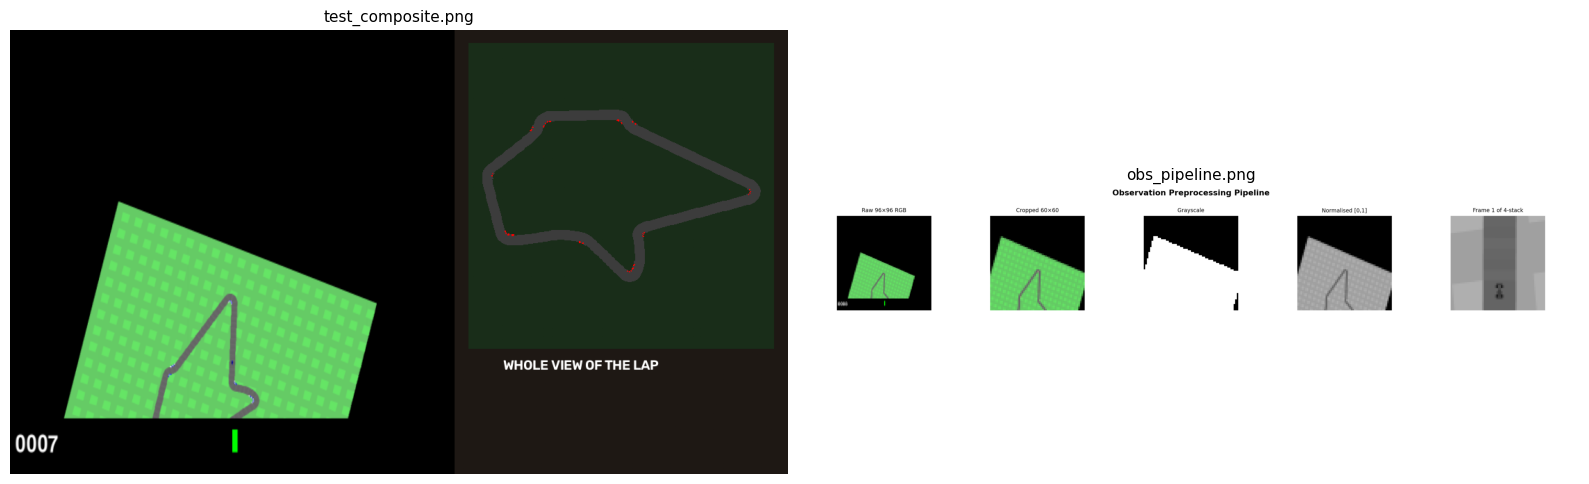

In [25]:
# Display a screenshot from the Learning Studio if available
studio_screenshots = [
    'assets/test_composite.png',
    'assets/obs_pipeline.png',
]

available = [p for p in studio_screenshots if os.path.exists(p)]
if available:
    fig, axes = plt.subplots(1, len(available), figsize=(8 * len(available), 6))
    if len(available) == 1:
        axes = [axes]
    for ax, path in zip(axes, available):
        img = plt.imread(path)
        ax.imshow(img)
        ax.set_title(os.path.basename(path), fontsize=11)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No Learning Studio screenshots found in assets/.")
    print("Run the studio once to generate them.")

---
## 13. Running the Pre-trained Agents (Quick Start)

The simplest way to see the agents in action is via `src/main.py`:

```bash
# Run PPO agent (default) with visual window
python src/main.py --agent PPO

# Run DQN agent with visual window
python src/main.py --agent DQN

# Headless evaluation only (no Pygame window)
python src/main.py --agent PPO --no-render
```

In [26]:
# 🚀 1-Click Launch: PPO Agent in Pygame Window
!python src/main.py --agent PPO



[CarRacing-v3] Running agent: PPO
Loading PPO model from c:\Users\HP\Desktop\CarRacing_v3_Shareable\models\true_ppo_data...

🏎️ Launching live visual simulation (render_mode='human')...
   -> Look for the 'CarRacing-v3' Pygame window on your screen!
   (Close the game window or press Ctrl+C to stop)
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Wrapping the env in a VecTransposeImage.
Simulation completed! Steps: 1000, Return: 837.11


In [27]:
# 🚀 1-Click Launch: DQN Agent in Pygame Window
!python src/main.py --agent DQN



[CarRacing-v3] Running agent: DQN
Loading DQN weights from c:\Users\HP\Desktop\CarRacing_v3_Shareable\models\true_dqn.pt...

🏎️ Launching live visual simulation (render_mode='human')...
   -> Look for the 'CarRacing-v3' Pygame window on your screen!
   (Close the game window or press Ctrl+C to stop)
Simulation completed! Steps: 238, Return: 887.98


In [28]:
# 🏎️ 1-Click Launch: Learning Studio with Minimap & Live Telemetry Window
!python src/lap_learning_studio.py --render --speed 2.0



   [CAR RACING v3: STEP-BY-STEP LEARNING STUDIO]
Target Episodes   : 50
Track Circuit Seed: 42 (Fixed path for consistent learning)
Off-Road Penalty  : -100.0 (triggers immediate restart)
Initial Sim Speed : 2.0x
Live GUI Window   : Enabled
Live Hotkeys      : [ + / UP ] Speed Up | [ - / DOWN ] Slow Down
                    [ SPACE ] Pause/Resume | [ M ] Turbo Max | [ R ] Reset 1x
Output Directory  : C:\Users\HP\Desktop\CarRacing_v3_Shareable\recorded_races

Ep   1/ 50 | Steps:  925 | Reward:  -203.7 | Progress:   8.1% | Epsilon: 0.992 | [OFF-ROAD RESTART]
   [VIDEO] Saved milestone clip: milestone_ep001.mp4
Ep   2/ 50 | Steps:  914 | Reward:  -194.5 | Progress:   8.8% | Epsilon: 0.984 | [OFF-ROAD RESTART]
   [OFF-ROAD VIDEO] Saved off-road clip: offroad_ep002.mp4 (restarts this session: 2)
Ep   3/ 50 | Steps:  972 | Reward:  -184.8 | Progress:  11.0% | Epsilon: 0.976 | [OFF-ROAD RESTART]
   [OFF-ROAD VIDEO] Saved off-road clip: offroad_ep003.mp4 (restarts this session: 3)
Ep   4/ 50 

---
## 14. Summary & Conclusions

### What we learned
- **CarRacing-v3** is a challenging pixel-based control task where the agent must learn to drive from raw images.
- Proper **observation preprocessing** (crop, grayscale, normalize, stack) is crucial for sample-efficient learning.
- **DQN** teaches the fundamentals of value-based RL: Q-learning, replay buffers, target networks, epsilon-greedy exploration.
- **PPO** offers a more modern, faster-converging alternative using policy gradient methods with clipped objectives.

### DQN vs PPO Summary

| Criterion | DQN | PPO |
|---|---|---|
| Training time | ~12h (600k steps) | ~2-4h |
| Sample efficiency | Lower (off-policy) | Higher (on-policy, but better updates) |
| Implementation | Custom (educational) | Library (production-ready) |
| Final performance | Good | Generally better |
| Stability | Requires tuning | More robust defaults |

### Possible Improvements
- **Double DQN / Dueling DQN** — Reduce overestimation bias in Q-values
- **Prioritized experience replay** — Focus on surprising transitions
- **Data augmentation** — Random crops/shifts for better generalization
- **Curriculum learning** — Start with simple tracks, increase difficulty
- **Reward shaping** — Add bonuses for staying centered on the road

In [29]:
print("=" * 50)
print("  🏁 Notebook complete!")
print("=" * 50)
print()
print("Project structure:")
print("  src/main.py               — Run pretrained agents")
print("  src/car_racing_training.py — Training pipeline")
print("  src/lap_learning_studio.py — Advanced learning studio")
print("  models/true_dqn.pt        — Trained DQN weights")
print("  models/true_ppo_data.zip   — Trained PPO weights")
print("  assets/                    — Images, CSVs, recordings")

  🏁 Notebook complete!

Project structure:
  src/main.py               — Run pretrained agents
  src/car_racing_training.py — Training pipeline
  src/lap_learning_studio.py — Advanced learning studio
  models/true_dqn.pt        — Trained DQN weights
  models/true_ppo_data.zip   — Trained PPO weights
  assets/                    — Images, CSVs, recordings
